In [180]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

In [181]:
import os
from PIL import Image
from IPython.display import display
import warnings

warnings.filterwarnings("ignore")

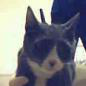

In [182]:
# Check the full file path!!
with Image.open("./Data/CATS_DOGS/test/CAT/10107.jpg") as im:
    display(im)

In [183]:
path = "./Data/CATS_DOGS/"
for i in os.walk(path):
    print(i)

('./Data/CATS_DOGS/', ['test', 'train'], [])
('./Data/CATS_DOGS/test', ['CAT', 'DOG'], [])
('./Data/CATS_DOGS/test\\CAT', [], ['10000.jpg', '10001.jpg', '10002.jpg', '10003.jpg', '10004.jpg', '10005.jpg', '10006.jpg', '10007.jpg', '10008.jpg', '10009.jpg', '10010.jpg', '10011.jpg', '10012.jpg', '10013.jpg', '10014.jpg', '10015.jpg', '10016.jpg', '10017.jpg', '10018.jpg', '10019.jpg', '10020.jpg', '10021.jpg', '10022.jpg', '10023.jpg', '10024.jpg', '10025.jpg', '10026.jpg', '10027.jpg', '10028.jpg', '10029.jpg', '10030.jpg', '10031.jpg', '10032.jpg', '10033.jpg', '10034.jpg', '10035.jpg', '10036.jpg', '10037.jpg', '10038.jpg', '10039.jpg', '10040.jpg', '10041.jpg', '10042.jpg', '10043.jpg', '10044.jpg', '10045.jpg', '10046.jpg', '10047.jpg', '10048.jpg', '10049.jpg', '10050.jpg', '10051.jpg', '10052.jpg', '10053.jpg', '10054.jpg', '10055.jpg', '10056.jpg', '10057.jpg', '10058.jpg', '10059.jpg', '10060.jpg', '10061.jpg', '10062.jpg', '10063.jpg', '10064.jpg', '10065.jpg', '10066.jpg', '1

In [184]:
path = "./Data/CATS_DOGS"
img_names = []

for i, (dirs, subdirs, filenames) in enumerate(os.walk(path)):
    print(i, dirs)
    print(i, subdirs)
    print(i, filenames)
    for img in filenames:
        img_names.append(dirs + "/" + img)

0 ./Data/CATS_DOGS
0 ['test', 'train']
0 []
1 ./Data/CATS_DOGS\test
1 ['CAT', 'DOG']
1 []
2 ./Data/CATS_DOGS\test\CAT
2 []
2 ['10000.jpg', '10001.jpg', '10002.jpg', '10003.jpg', '10004.jpg', '10005.jpg', '10006.jpg', '10007.jpg', '10008.jpg', '10009.jpg', '10010.jpg', '10011.jpg', '10012.jpg', '10013.jpg', '10014.jpg', '10015.jpg', '10016.jpg', '10017.jpg', '10018.jpg', '10019.jpg', '10020.jpg', '10021.jpg', '10022.jpg', '10023.jpg', '10024.jpg', '10025.jpg', '10026.jpg', '10027.jpg', '10028.jpg', '10029.jpg', '10030.jpg', '10031.jpg', '10032.jpg', '10033.jpg', '10034.jpg', '10035.jpg', '10036.jpg', '10037.jpg', '10038.jpg', '10039.jpg', '10040.jpg', '10041.jpg', '10042.jpg', '10043.jpg', '10044.jpg', '10045.jpg', '10046.jpg', '10047.jpg', '10048.jpg', '10049.jpg', '10050.jpg', '10051.jpg', '10052.jpg', '10053.jpg', '10054.jpg', '10055.jpg', '10056.jpg', '10057.jpg', '10058.jpg', '10059.jpg', '10060.jpg', '10061.jpg', '10062.jpg', '10063.jpg', '10064.jpg', '10065.jpg', '10066.jpg', '10

In [185]:
len(img_names)

24994

In [186]:
img_sizes = []
rejected = []

for item in img_names:
    try:
        with Image.open(item) as img:
            img_sizes.append(img.size)

    except:
        rejected.append(item)

In [187]:
print(len(img_sizes), len(rejected))

24994 0


In [188]:
df = pd.DataFrame(img_sizes)

In [189]:
df.head()

,0,1
0,431,360
1,500,375
2,500,471
3,500,375
4,320,240


In [190]:
df.value_counts()

0    1  
500  375    5867
375  500     488
500  333     427
320  240     399
500  374     189
            ... 
280  236       1
     233       1
     232       1
     226       1
320  264       1
Length: 7509, dtype: int64

In [191]:
df.describe()  # 0 Width 1 Height

,0,1
count,24994.000000,24994.000000
mean,404.493518,361.037129
std,108.941802,96.936811
min,42.000000,33.000000
25%,323.000000,302.000000
50%,448.000000,375.000000
75%,500.000000,421.000000
max,500.000000,500.000000


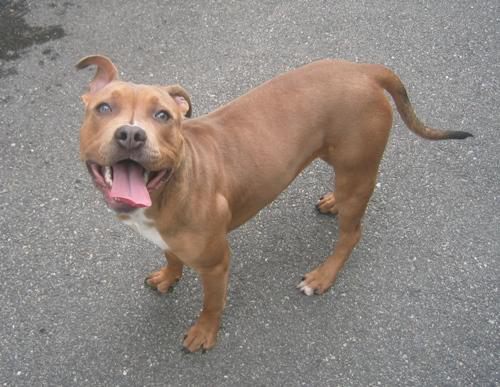

In [192]:
dog = Image.open("./Data/CATS_DOGS/train/DOG/14.jpg")
display(dog)

In [193]:
dog.size

(500, 387)

In [194]:
dog.getpixel((0, 0))

(90, 95, 98)

In [195]:
transform = transforms.Compose(
    [
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(30),
        # transforms.RandomRotation(10,interpolation=transforms.InterpolationMode.BICUBIC),
        # transforms.RandomRotation(10,expand=True),
        transforms.ToTensor(),
        transforms.Resize((250)),
        transforms.CenterCrop(250),
    ]
)
transform01 = transforms.Compose(
    [
        transforms.CenterCrop((250, 150)),
        # transforms.Resize((224,224)),
        transforms.ToTensor(),
    ]
)
transform02 = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.CenterCrop(25),
        transforms.Resize((250)),
        # transforms.CenterCrop((250,))
    ]
)
# toTensor = transforms.ToTensor()
# transform1 = transforms.Resize((200,))
# transform2 = transforms.Resize((200,400))

In [196]:
def shows(image=dog):
    im = transform(dog)
    im01 = transform01(dog)
    im02 = transform02(dog)
    # dog1 = transform1(dog)
    # dog2 = transform2(dog)
    # im1 = toTensor(dog1)
    # im2 = toTensor(dog2)
    print(type(im))
    print(dog.size, im01.shape, im02.shape)
    # print(dog.size,dog1.size,dog2.size,im01.shape,im02.shape)
    # print(dog.size,im1.shape,im2.shape)
    plt.imshow(im.permute(1, 2, 0))
    return im.permute(1, 2, 0)

<class 'torch.Tensor'>
(500, 387) torch.Size([3, 250, 150]) torch.Size([3, 250, 250])


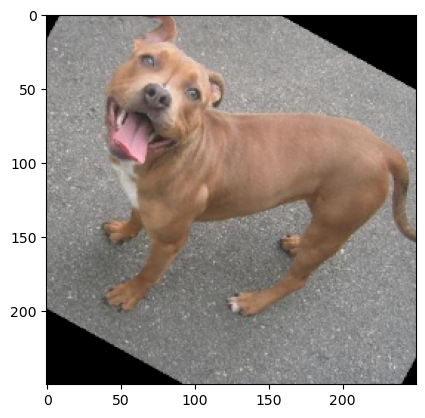

In [197]:
im = shows()

In [198]:
transform = transforms.Compose(
    [
        transforms.ToTensor(),
    ]
)
transform01 = transforms.Compose(
    [
        transforms.CenterCrop((250, 150)),
        # transforms.Resize((224,224)),
        transforms.ToTensor(),
    ]
)
transform02 = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.CenterCrop(25),
        transforms.Resize((250)),
        # transforms.CenterCrop((250,))
    ]
)

In [199]:
def shows(image=dog):
    im = transform(dog)
    im01 = transform01(dog)
    im02 = transform02(dog)
    # dog1 = transform1(dog)
    # dog2 = transform2(dog)
    # im1 = toTensor(dog1)
    # im2 = toTensor(dog2)
    print(type(im))
    print(dog.size, im01.shape, im02.shape)
    # print(dog.size,dog1.size,dog2.size,im01.shape,im02.shape)
    # print(dog.size,im1.shape,im2.shape)
    plt.imshow(im.permute(1, 2, 0))
    return im.permute(1, 2, 0)

In [200]:
# print(im[:, 0, 0])

In [201]:
sum([0.485, 0.456, 0.406])

1.347

In [ ]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]


transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(30),
        transforms.Resize((224)),
        transforms.CenterCrop(224),
    ]
)


In [215]:
def shows(image=dog):
    im = transform(dog)
    # print(type(im))
    plt.imshow(im.permute(1, 2, 0))
    return im, im.permute(1, 2, 0)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


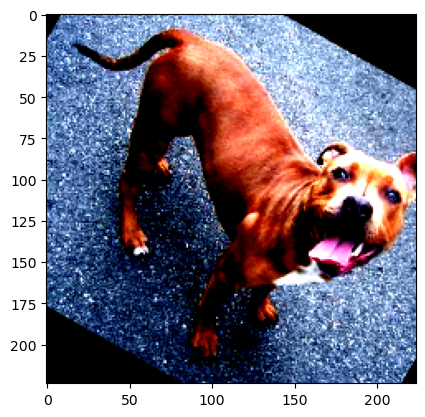

In [216]:
im, imt = shows(dog)

In [ ]:
mean_inv = [-m / s for m, s in zip(mean, std)]
mean_inv

[-2.1179039301310043, -2.0357142857142856, -1.8044444444444445]

In [ ]:
std_inv = [1 / s for s in std]
std_inv

[4.366812227074235, 4.464285714285714, 4.444444444444445]

In [ ]:
inv_normalize = transforms.Normalize(mean=mean_inv, std=std_inv)

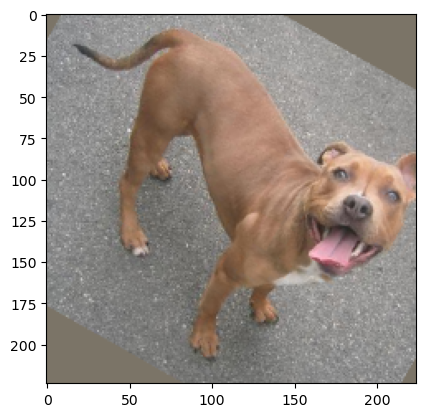

In [218]:
im_inv = inv_normalize(im)
# plt.figure(figsize = (12,4))
plt.imshow(im_inv.permute(1, 2, 0))